# 1. Problem — pressure as a spatial inverse problem
Recover fluid pressure from two calibrated gradient images. Gradients remove the additive pressure constant, and missing exterior edges make the boundary part of the inverse problem. This notebook actively reconstructs the complete bound **1001×1001 native author grid**, then computes all comparisons and sensitivity experiments.

The source is the published one-shot omnidirectional method, with unchanged boundary weights and float32 CPU conjugate-gradient updates. The data are **new simulated observations from the author's specified Taylor-vortex model**, not measured PIV images. An analytic pressure field provides independent physical truth. Reproduced original results are labeled separately from fresh local computations.

In [1]:
from pathlib import Path
import sys, os, time, json, importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
if not Path("src").exists():
    os.chdir(Path.cwd().parent)
from src.preprocessing import load_data, PRESSURE_SCALE_PA
from src.physics_model import spacing, matrix_apply, build_rhs, edge_residual
from src.solvers import solve
from src.generate_data import generate
from src import visualization as vis
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
g,q=load_data()
truth=np.load("evaluation/ground_truth.npz")["reconstruction"][0]
upstream=np.load("notebooks/reference_outputs/upstream_measurements.npz")["reconstruction"][0]
print({"gradient_shape":g.shape,"gradient_dtype":str(g.dtype),"spacing_first_stored":float(spacing(q)),"pressure_scale_Pa":PRESSURE_SCALE_PA})

{'gradient_shape': (2, 1001, 1001), 'gradient_dtype': 'float32', 'spacing_first_stored': 0.006000041961669922, 'pressure_scale_Pa': 0.001}


# 2. Data — full native acquisition
The author uses normalized coordinates from −3 to3; physical length scale is1mm and pressure scale1mPa. Inputs preserve float32 VTK quantization. Components are x,y, and image arrays have y,x axes. The gradient is obtained from finite-difference convective acceleration, so it includes deterministic sampling error even with no added random noise. The pressure datum is fixed at zero-based pixel(1,1), matching the author's displayed pressure gauge. Neither an analytic object formula nor its pressure image is a released solver input.

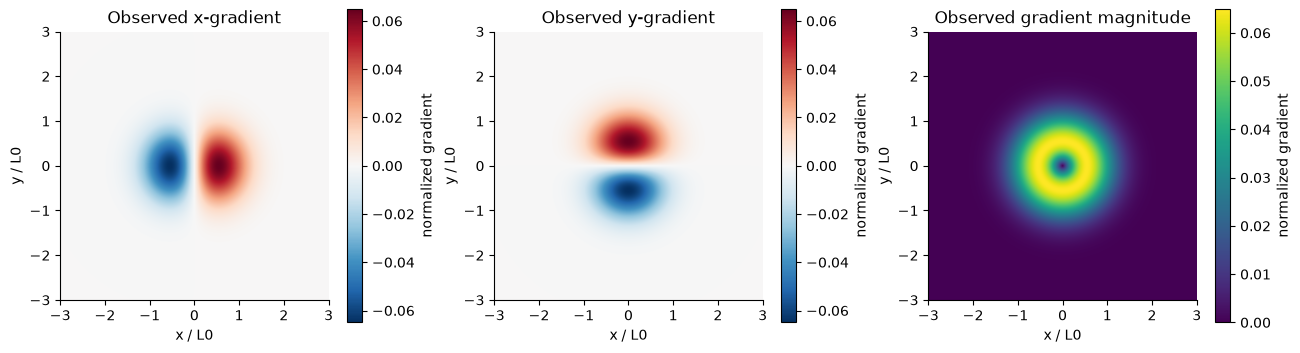

In [2]:
fig=vis.images([g[0],g[1],np.hypot(g[0],g[1])],["Observed x-gradient","Observed y-gradient","Observed gradient magnitude"],"01_gradient_observations",unit="normalized gradient",cmap=["RdBu_r","RdBu_r","viridis"],symmetric=[True,True,False],shared=False)
display(fig);plt.close(fig)

# 3. Physics — gradient integration with incomplete boundaries
For an edge from pixel i to adjacent j, measured normalized pressure increment is the average of the corresponding gradient components times edge spacing. With incidence matrix B and diagonal positive edge weights C, the normal equations are

$$ A p^*=b,\qquad A=B^T C B,\qquad b=B^T C d. $$

Here normalized pressure is $p^*=p/P_0$, d contains measured increments, and missing exterior edges are omitted. On a square grid each edge weight is1/4. The diagonal is1 internally,3/4 on an edge, and1/2 at a corner. Thus constants lie in A's nullspace and the graph energy is nonnegative. The plots below evaluate the local operator; they do not replace independent frozen original stage tests.

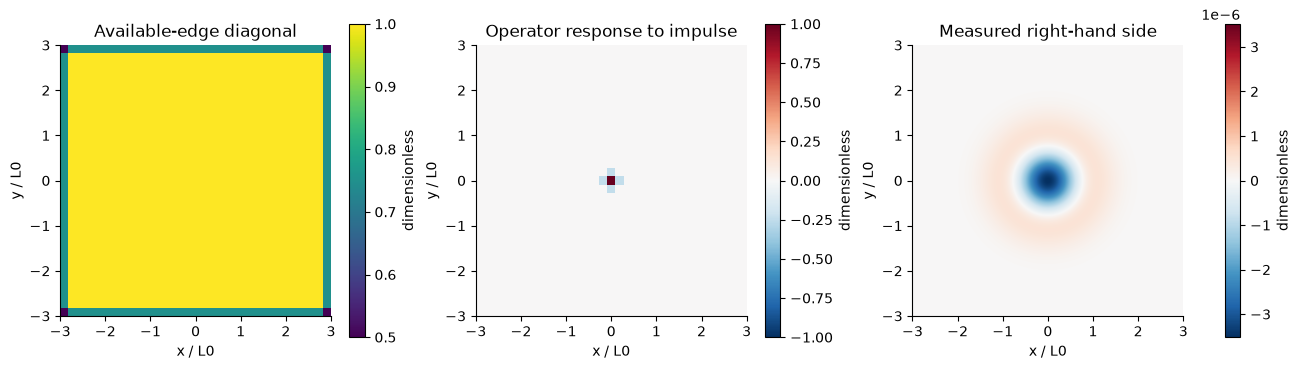

Constant nullspace verified; independent adjoint, energy and affine checks are in test/.


In [3]:
h=spacing(q)
impulse=np.zeros((33,33),np.float32);impulse[16,16]=1
probe=matrix_apply(impulse,h)
degree=np.ones((33,33),np.float32);degree[[0,-1],:]-=.25;degree[:,[0,-1]]-=.25
rhs=build_rhs(g,h)
fig=vis.images([degree,probe,rhs],["Available-edge diagonal","Operator response to impulse","Measured right-hand side"],"02_boundary_operator_physics",unit="dimensionless",cmap=["viridis","RdBu_r","RdBu_r"],symmetric=[False,True,True],shared=False)
display(fig);plt.close(fig)
assert np.array_equal(matrix_apply(np.ones((33,33),np.float32),h),np.zeros((33,33),np.float32))
print("Constant nullspace verified; independent adjoint, energy and affine checks are in test/.")

# 4. Method — active native-grid inversion
Minimize half the weighted squared disagreement between pressure increments and measured gradient increments, with no extra smoothing penalty. Starting at zero pressure, standard conjugate-gradient updates use the boundary-aware matrix product. The original implicit residual update stops when **either** relative norm reaches1e−4 **or** absolute norm reaches1e−6. Dot products preserve single-thread float32 summation order. Pressure is converted to Pa after applying the fixed datum. This cell computes the full benchmark reconstruction; it never loads an archived map as a fresh result.

In [4]:
start=time.perf_counter()
fresh,history=solve(g,q)
fresh_seconds=time.perf_counter()-start
Path("output").mkdir(exist_ok=True)
np.savez_compressed("output/reconstruction.npz",reconstruction=fresh[None])
spec=importlib.util.spec_from_file_location("pressure_judge",Path("evaluation/judge.py"));judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate("output/reconstruction.npz")
Path("output/judge_report.json").write_text(json.dumps(report,indent=2,allow_nan=False),encoding="utf-8")
assert report["passed"],report
assert np.array_equal(fresh,upstream)
assert vis.metrics(np.array([1.,3.]),np.array([2.,4.]))["nrmse"]==.5
assert vis.metrics(fresh,truth)==report["metrics"]
print(json.dumps({"fresh_runtime_seconds":fresh_seconds,"updates":len(history),"judge":report,"bitwise_equal_to_original":True},indent=2))

{
  "fresh_runtime_seconds": 74.27977870000177,
  "updates": 1546,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "ncc": 0.9999997406798782,
      "nrmse": 0.00016835737028257186
    },
    "thresholds": {
      "ncc": {
        "comparison": ">=",
        "boundary": 0.8999997666118912
      },
      "nrmse": {
        "comparison": "<=",
        "boundary": 0.00018519310731082906
      }
    },
    "errors": []
  },
  "bitwise_equal_to_original": true
}


# 5. Results — independent truth, original run and fresh computation
All maps use the same physical scale, coordinate axes and fixed datum. Analytic truth is independent of the inverse solver. The original CPU reconstruction was captured by executing the unmodified author source on these exact gradient observations; the fresh map was computed above. NCC is flattened cosine similarity, and NRMSE is RMS error divided by analytic pressure dynamic range. No alignment or fitted rescaling is used.

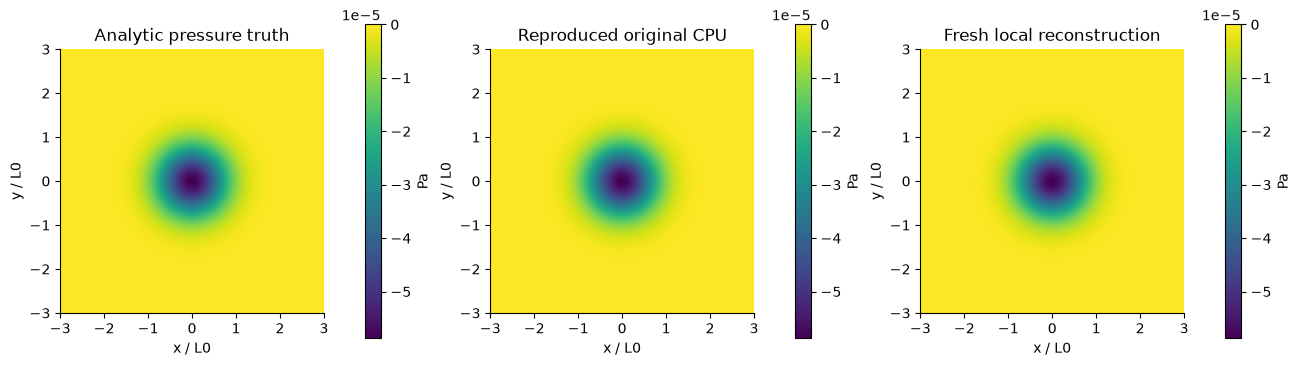

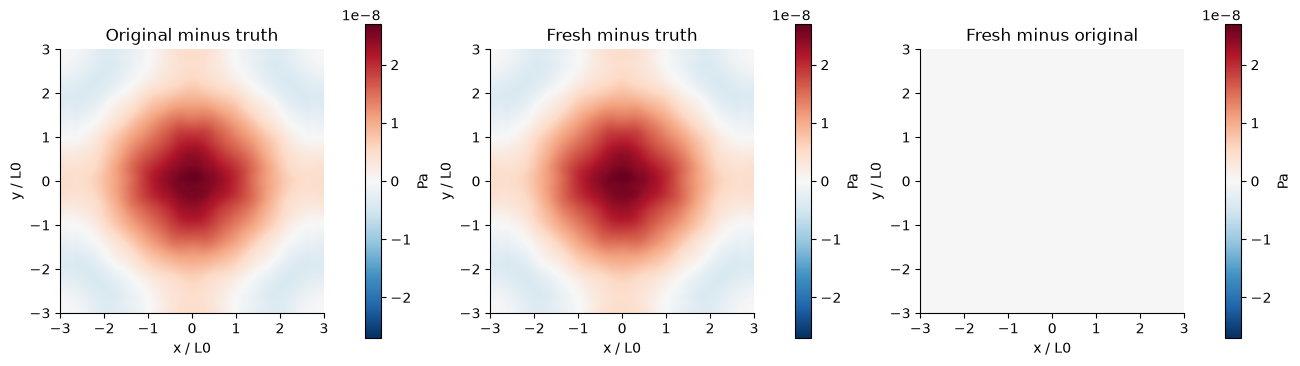

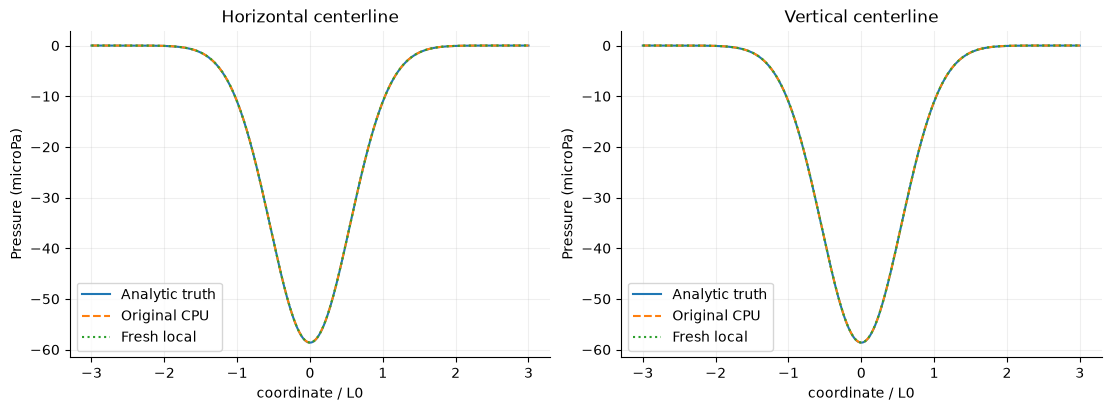

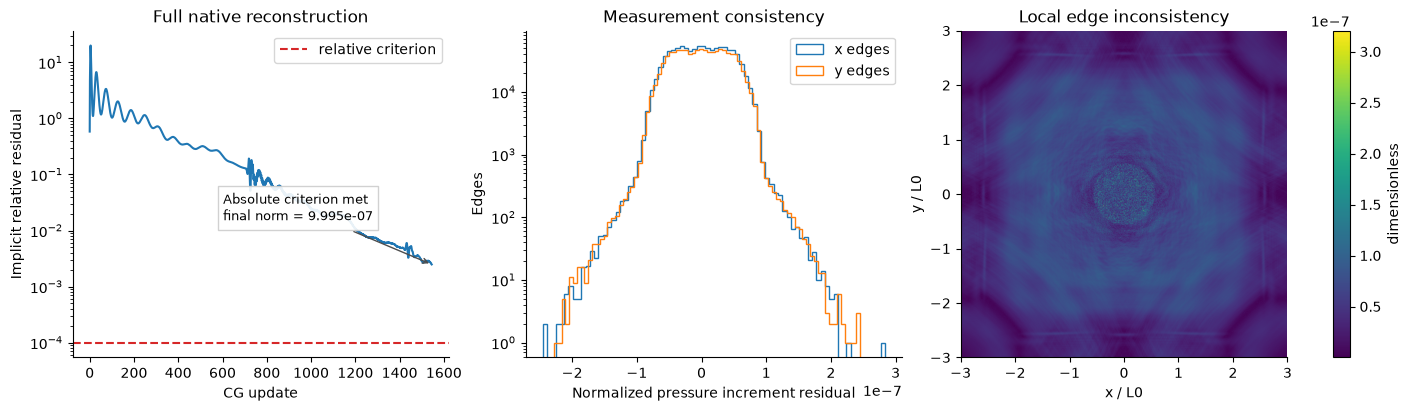

{
  "original_vs_truth": {
    "ncc": 0.9999997406798782,
    "nrmse": 0.00016835737028257186
  },
  "fresh_vs_truth": {
    "ncc": 0.9999997406798782,
    "nrmse": 0.00016835737028257186
  },
  "fresh_vs_original": {
    "ncc": 1.0,
    "nrmse": 0.0
  },
  "edge_residual_RMS": 4.0494723684330915e-08
}


In [5]:
fig=vis.images([truth,upstream,fresh],["Analytic pressure truth","Reproduced original CPU","Fresh local reconstruction"],"03_pressure_comparison",unit="Pa")
display(fig);plt.close(fig)
fig=vis.images([upstream-truth,fresh-truth,fresh-upstream],["Original minus truth","Fresh minus truth","Fresh minus original"],"04_pressure_error_maps",unit="Pa",cmap="RdBu_r",symmetric=True)
display(fig);plt.close(fig)
fig=vis.line_profiles(q,truth,upstream,fresh);display(fig);plt.close(fig)
rx,ry=edge_residual(fresh/PRESSURE_SCALE_PA,g,h)
fig=vis.residuals(history,rx,ry);display(fig);plt.close(fig)
print(json.dumps({"original_vs_truth":vis.metrics(upstream,truth),"fresh_vs_truth":vis.metrics(fresh,truth),"fresh_vs_original":vis.metrics(fresh,upstream),"edge_residual_RMS":float(np.sqrt((np.sum(rx**2)+np.sum(ry**2))/(rx.size+ry.size)))},indent=2))

## Actual stopping-tolerance experiment
The next two native-grid reconstructions change only the absolute stopping tolerance, keeping the source relative tolerance, observations, weights, initialization and float32 updates. These are computed results. They are sensitivity measurements, not additional benchmark tasks or replacements for the selected default method.

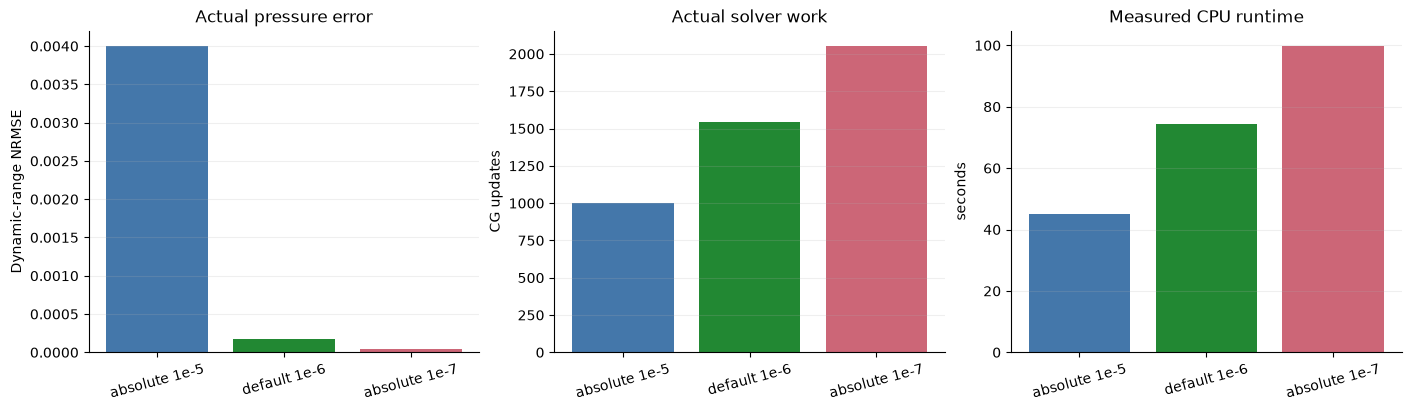

[
  {
    "label": "absolute 1e-5",
    "absolute_tolerance": 1e-05,
    "ncc": 0.9997548385253361,
    "nrmse": 0.004001068780182873,
    "iterations": 999,
    "seconds": 45.12118100000953,
    "final_relative_residual": 0.024566829085364266,
    "final_absolute_residual": 9.885609004001155e-06
  },
  {
    "label": "default 1e-6",
    "absolute_tolerance": 1e-06,
    "ncc": 0.9999997406798782,
    "nrmse": 0.00016835737028257186,
    "iterations": 1546,
    "seconds": 74.27977870000177,
    "final_relative_residual": 0.0024839680603250345,
    "final_absolute_residual": 9.995403532737342e-07
  },
  {
    "label": "absolute 1e-7",
    "absolute_tolerance": 1e-07,
    "ncc": 0.9999999781833577,
    "nrmse": 4.0101608796438617e-05,
    "iterations": 2053,
    "seconds": 99.78011680000054,
    "final_relative_residual": 0.00024748949441592166,
    "final_absolute_residual": 9.958893619898572e-08
  }
]


In [6]:
rows=[];sensitivity_maps={}
for atol,label in [(1e-5,"absolute 1e-5"),(1e-6,"default 1e-6"),(1e-7,"absolute 1e-7")]:
    if atol==1e-6:p,hist,seconds=fresh,history,fresh_seconds
    else:
        start=time.perf_counter();p,hist=solve(g,q,absolute_tolerance=atol);seconds=time.perf_counter()-start
    rows.append({"label":label,"absolute_tolerance":atol,**vis.metrics(p,truth),"iterations":len(hist),"seconds":seconds,"final_relative_residual":float(hist[-1,1]),"final_absolute_residual":float(hist[-1,2])})
    sensitivity_maps[label]=p
fig=vis.sensitivity(rows);display(fig);plt.close(fig)
print(json.dumps(rows,indent=2))

## Actual sampling and noise experiments
The129² and257² grids preserve the author's continuous physical model, domain, constants and coordinate convention. Their independent original parity fixtures verify complete pressure reconstruction. Analytic gradient error decreases with sampling refinement. Pressure error under the unchanged absolute stopping criterion need not decrease monotonically, because the RHS norm also decreases with spacing. Additional129² trials add independently sampled Gaussian gradient noise at1% and5% of gradient RMS and actively reconstruct each perturbed acquisition. These are controlled robustness studies with known synthetic truth.

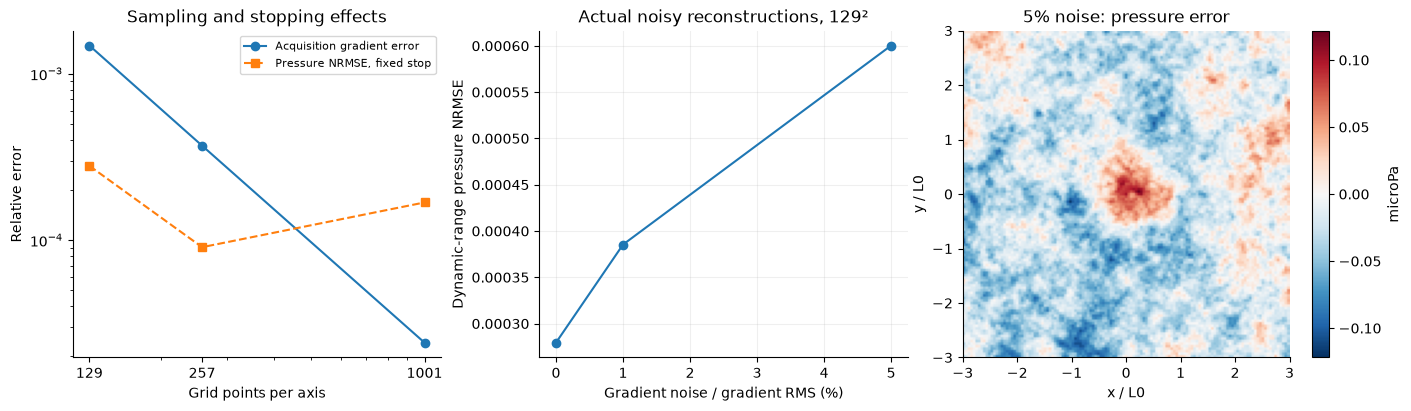

{
  "fresh_seconds": 74.27977870000177,
  "fresh_metrics": {
    "ncc": 0.9999997406798782,
    "nrmse": 0.00016835737028257186
  },
  "stopping_sensitivity": [
    {
      "label": "absolute 1e-5",
      "absolute_tolerance": 1e-05,
      "ncc": 0.9997548385253361,
      "nrmse": 0.004001068780182873,
      "iterations": 999,
      "seconds": 45.12118100000953,
      "final_relative_residual": 0.024566829085364266,
      "final_absolute_residual": 9.885609004001155e-06
    },
    {
      "label": "default 1e-6",
      "absolute_tolerance": 1e-06,
      "ncc": 0.9999997406798782,
      "nrmse": 0.00016835737028257186,
      "iterations": 1546,
      "seconds": 74.27977870000177,
      "final_relative_residual": 0.0024839680603250345,
      "final_absolute_residual": 9.995403532737342e-07
    },
    {
      "label": "absolute 1e-7",
      "absolute_tolerance": 1e-07,
      "ncc": 0.9999999781833577,
      "nrmse": 4.0101608796438617e-05,
      "iterations": 2053,
      "seconds": 99.780

In [7]:
grid_rows=[]
for n in [129,257,1001]:
    gg,qq,tt=generate(n)
    if n==1001:pp=fresh
    else:pp,_=solve(gg,qq)
    x,y=np.meshgrid(qq.astype(float)*.001,qq.astype(float)*.001)
    C=1000*1e-12/(64*np.pi**2*1e-6*.3**3)
    e=np.exp(-(x*x+y*y)/(2*1e-6*.3));analytic=np.stack([C*e*x/(1e-6*.3),C*e*y/(1e-6*.3)])
    grid_rows.append({"n":n,**vis.metrics(pp,tt),"derivative_error":float(np.linalg.norm(gg-analytic)/np.linalg.norm(analytic))})
gg,qq,tt=generate(129);rng=np.random.default_rng(20261022);noise_rows=[];noise_maps={}
for fraction in [0.,.01,.05]:
    noisy=(gg+fraction*float(np.sqrt(np.mean(gg.astype(float)**2)))*rng.normal(size=gg.shape)).astype(np.float32)
    pp,hh=solve(noisy,qq)
    noise_rows.append({"noise":fraction,**vis.metrics(pp,tt),"iterations":len(hh)})
    noise_maps[str(fraction)]=pp
fig=vis.grid_noise(grid_rows,noise_rows,noise_maps["0.05"]-tt);display(fig);plt.close(fig)
measurements={"fresh_seconds":fresh_seconds,"fresh_metrics":report["metrics"],"stopping_sensitivity":rows,"grid_study":grid_rows,"noise_study":noise_rows}
print(json.dumps(measurements,indent=2))
if os.environ.get("IMAGING_FIGURE_DIR"):
    directory=Path(os.environ["IMAGING_FIGURE_DIR"])
    (directory/"scientific_measurements.json").write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding="utf-8")
    np.savez_compressed(directory/"numerical_sources.npz",coordinate=q,gradient=g,truth=truth,upstream=upstream,fresh=fresh,history=history,edge_x=rx,edge_y=ry,loose=sensitivity_maps["absolute 1e-5"],strict=sensitivity_maps["absolute 1e-7"],noise_0=noise_maps["0.0"],noise_1percent=noise_maps["0.01"],noise_5percent=noise_maps["0.05"])

# 6. Conclusion — what the evidence establishes
The complete native-grid fresh reconstruction is independently evaluated against analytic physical pressure and compared with the original method on the exact bound observations. Stage parity covers boundary-aware RHS, matrix product and first CG update; mathematical tests cover nullspace, positive energy, symmetry, affine-gradient compatibility and analytic acquisition derivatives. Finite-difference gradient error and float32 stopping error are distinct sources of reconstruction error.

This is a controlled author-defined simulation, so it does not establish accuracy on noisy experimental PIV or turbulent flows. The reference implementation preserves the author's implicit-residual stopping convention and does not silently replace it with a stricter method. The notebook retains the original truth/reconstruction comparison and adds computed residuals, stopping sensitivity, grid sampling and noise robustness. Every plotted reconstruction above was either clearly identified as the archived original run or actively computed by local mathematics.